<a href="https://colab.research.google.com/github/Basma328/Beginning_Bioinformatics/blob/main/visualization%20part%20explain%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Install UMAP and import the tools

In [1]:
%pip -q install umap-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from google.colab import files
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

2. Read the cleaned data and training IDs
This cell finds the cleaned dataset as either .csv or .csv.gz, reads it, and reads training_ids.csv.

In [2]:
DATA_DIR = Path("/content")

cleaned_options = sorted(DATA_DIR.glob("camptothecin_cleaned_full.csv*"))
training_file = DATA_DIR / "training_ids.csv"

if not cleaned_options:
    raise FileNotFoundError(
        "Could not find camptothecin_cleaned_full.csv or .csv.gz in /content."
    )

if not training_file.exists():
    raise FileNotFoundError("Could not find training_ids.csv in /content.")

# Prefer the compressed file if both versions are present
cleaned_file = next(
    (path for path in cleaned_options if path.name.lower().endswith(".csv.gz")),
    cleaned_options[0]
)

data = pd.read_csv(cleaned_file, compression="infer")
training_ids_df = pd.read_csv(training_file)

# Clean column names
data.columns = (
    data.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)
training_ids_df.columns = (
    training_ids_df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

print("Cleaned dataset:", cleaned_file.name)
print("Training IDs file:", training_file.name)
print("Dataset dimensions:", data.shape)

Cleaned dataset: camptothecin_cleaned_full.csv
Training IDs file: training_ids.csv
Dataset dimensions: (579, 54140)


3. Select the 463 training cell lines
This cell checks IDs and keeps only the cell lines listed in training_ids.csv. The order follows that file.

In [3]:
if "sampleId" not in data.columns:
    raise ValueError("The cleaned dataset needs a 'sampleId' column.")

if "sampleId" not in training_ids_df.columns:
    raise ValueError("training_ids.csv needs a 'sampleId' column.")

if not {"cancer_type", "AUC"}.issubset(data.columns):
    raise ValueError("The cleaned dataset needs 'cancer_type' and 'AUC' columns.")

data["sampleId"] = data["sampleId"].astype("string").str.strip()
training_ids_df["sampleId"] = (
    training_ids_df["sampleId"].astype("string").str.strip()
)

if data["sampleId"].isna().any() or (data["sampleId"] == "").any():
    raise ValueError("Blank sample IDs found in the cleaned dataset.")

if training_ids_df["sampleId"].isna().any() or (
    training_ids_df["sampleId"] == ""
).any():
    raise ValueError("Blank sample IDs found in training_ids.csv.")

if data["sampleId"].duplicated().any():
    raise ValueError("Duplicate sample IDs found in the cleaned dataset.")

if training_ids_df["sampleId"].duplicated().any():
    raise ValueError("Duplicate sample IDs found in training_ids.csv.")

training_ids = training_ids_df["sampleId"].astype(str).tolist()

if len(training_ids) != 463:
    raise ValueError(f"Expected 463 training IDs; found {len(training_ids)}.")

data["sampleId"] = data["sampleId"].astype(str)
data = data.set_index("sampleId", drop=False)

missing_ids = [sid for sid in training_ids if sid not in data.index]
if missing_ids:
    raise ValueError(
        f"{len(missing_ids)} training IDs were not found. "
        f"Examples: {missing_ids[:10]}"
    )

train = data.loc[training_ids].copy()

print("Matched training cell lines:", len(train))
print("Cancer types represented:", train["cancer_type"].nunique())

Matched training cell lines: 463
Cancer types represented: 35


4. Prepare the gene-expression inputs
Only gene-expression columns go into PCA and UMAP. The code keeps cancer type and AUC separate for coloring the plots. It transforms RPKM with log2(RPKM + 1), removes incomplete and constant genes, then standardizes each gene.

In [4]:
# Keep labels separate; they will only be used to color the plots
plot_metadata = train[["sampleId", "cancer_type", "AUC"]].copy()
plot_metadata["cancer_type"] = plot_metadata["cancer_type"].astype(str)
plot_metadata["AUC"] = pd.to_numeric(plot_metadata["AUC"], errors="coerce")

if plot_metadata[["cancer_type", "AUC"]].isna().any().any():
    raise ValueError("Missing cancer type or invalid AUC in training data.")

# Exclude metadata columns from the analysis inputs
metadata_columns = {"sampleId", "cancer_type", "AUC"}
gene_columns = [col for col in train.columns if col not in metadata_columns]

if not gene_columns:
    raise ValueError("No gene-expression columns were found.")

# Convert expression values to numbers
X_rpkm = train[gene_columns].apply(pd.to_numeric, errors="coerce")
X_rpkm = X_rpkm.replace([np.inf, -np.inf], np.nan)

# Remove genes with missing or invalid values
invalid_gene_mask = X_rpkm.isna().any(axis=0)
invalid_gene_count = int(invalid_gene_mask.sum())
X_rpkm = X_rpkm.loc[:, ~invalid_gene_mask]

if X_rpkm.shape[1] == 0:
    raise ValueError("No complete numeric gene-expression columns remain.")

if (X_rpkm < 0).any().any():
    raise ValueError("Negative RPKM values found; log2(RPKM + 1) requires non-negative values.")

# Transform RPKM values
X_log = np.log2(X_rpkm + 1)

# Remove genes that do not vary across the training cell lines
constant_gene_mask = X_log.nunique(axis=0, dropna=False) <= 1
constant_gene_count = int(constant_gene_mask.sum())
X_log = X_log.loc[:, ~constant_gene_mask]

if X_log.shape[1] == 0:
    raise ValueError("No variable genes remain after filtering.")

# Standardize each gene across the 463 training cell lines
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Starting gene columns:", len(gene_columns))
print("Genes removed for missing/invalid values:", invalid_gene_count)
print("Constant genes removed:", constant_gene_count)
print("Genes retained:", X_log.shape[1])
print("Final expression matrix dimensions:", X_scaled.shape)

Starting gene columns: 54137
Genes removed for missing/invalid values: 0
Constant genes removed: 3653
Genes retained: 50484
Final expression matrix dimensions: (463, 50484)


5. Run PCA and create the scree plot
PCA uses the standardized expression matrix. PC1 and PC2 form the 2D map; the scree plot shows how much variation the leading components explain.

PC1 variance explained: 4.98%
PC2 variance explained: 3.36%
PC1 + PC2 variance explained: 8.34%


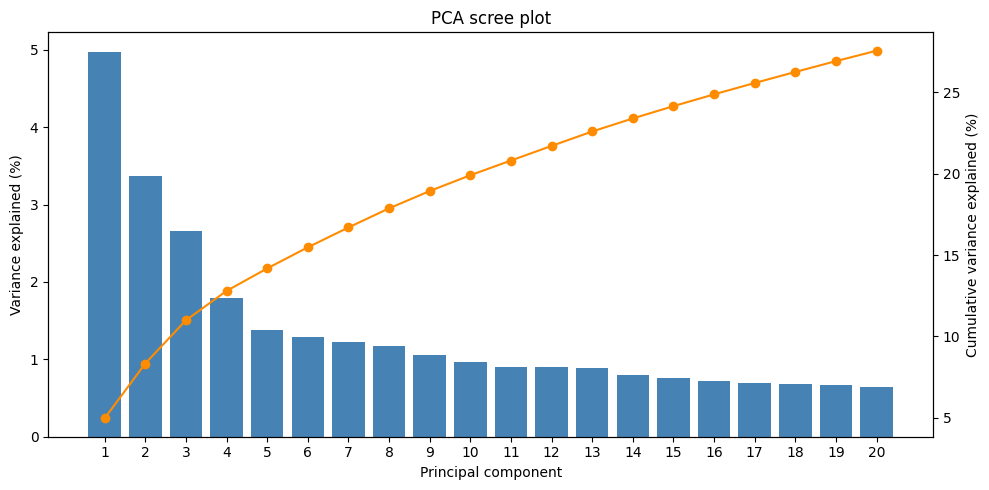

In [5]:
N_PCS = min(50, X_scaled.shape[0] - 1, X_scaled.shape[1])

pca = PCA(
    n_components=N_PCS,
    svd_solver="randomized",
    random_state=SEED
)

pca_scores = pca.fit_transform(X_scaled)
pca_coordinates = pca_scores[:, :2]
explained = pca.explained_variance_ratio_

print(f"PC1 variance explained: {explained[0] * 100:.2f}%")
print(f"PC2 variance explained: {explained[1] * 100:.2f}%")
print(f"PC1 + PC2 variance explained: {explained[:2].sum() * 100:.2f}%")

# Scree plot for up to the first 20 PCs
number_to_plot = min(20, N_PCS)
components = np.arange(1, number_to_plot + 1)
variance_percent = explained[:number_to_plot] * 100
cumulative_percent = np.cumsum(variance_percent)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(components, variance_percent, color="steelblue")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)")
ax1.set_xticks(components)
ax1.set_title("PCA scree plot")

ax2 = ax1.twinx()
ax2.plot(components, cumulative_percent, color="darkorange", marker="o")
ax2.set_ylabel("Cumulative variance explained (%)")

plt.tight_layout()
plt.show()

Explain:Blue bars: how much of the expression variation each principal component explains individually.
Orange line: how much variation is explained cumulatively as more components are included.
Your PC1 explains 4.98% and PC2 explains 3.36%; together, they explain 8.34%.
This plot helps show how much information is compressed into the components. The components are summaries of many genes, not individual cell lines or genes. **bold text**

6. Plot PCA by cancer type and AUC
This function uses the same PCA coordinates for both plots. Cancer type is categorical; AUC uses a continuous color scale.

In [10]:
print(f"First {N_PCS} PCs explain {explained.sum() * 100:.2f}% of variance")

First 50 PCs explain 40.56% of variance


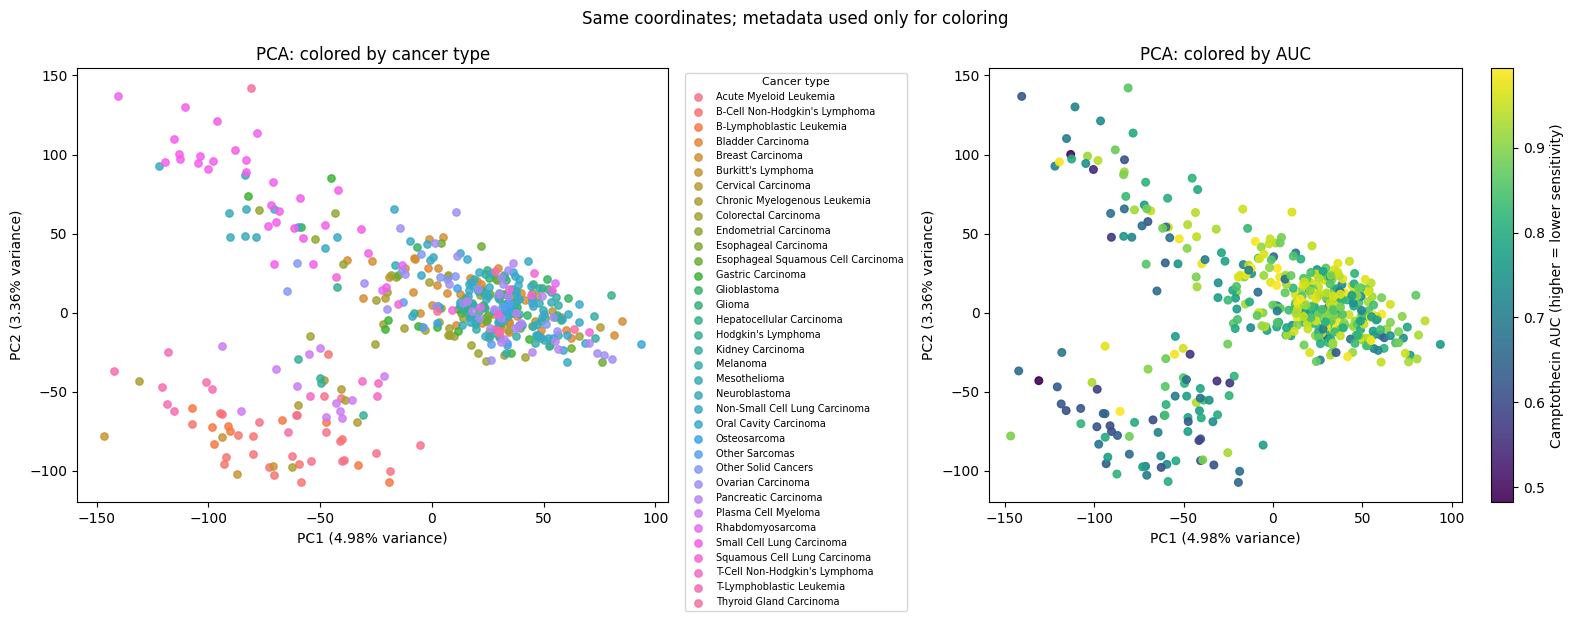

In [6]:
def plot_embedding(coords, axis_labels, method_name):
    cancer_types = plot_metadata["cancer_type"].to_numpy()
    auc_values = plot_metadata["AUC"].to_numpy(dtype=float)
    categories = sorted(pd.unique(cancer_types))
    colors = sns.color_palette("husl", n_colors=len(categories))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Same coordinates, colored by cancer type
    for cancer, color in zip(categories, colors):
        mask = cancer_types == cancer
        axes[0].scatter(
            coords[mask, 0],
            coords[mask, 1],
            color=color,
            label=cancer,
            s=28,
            alpha=0.82
        )

    axes[0].set_xlabel(axis_labels[0])
    axes[0].set_ylabel(axis_labels[1])
    axes[0].set_title(f"{method_name}: colored by cancer type")
    axes[0].legend(
        title="Cancer type",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=7,
        title_fontsize=8
    )

    # Same coordinates, colored by continuous AUC
    points = axes[1].scatter(
        coords[:, 0],
        coords[:, 1],
        c=auc_values,
        cmap="viridis",
        s=30,
        alpha=0.9
    )

    colorbar = fig.colorbar(points, ax=axes[1])
    colorbar.set_label("Camptothecin AUC (higher = lower sensitivity)")
    axes[1].set_xlabel(axis_labels[0])
    axes[1].set_ylabel(axis_labels[1])
    axes[1].set_title(f"{method_name}: colored by AUC")

    fig.suptitle("Same coordinates; metadata used only for coloring")
    plt.tight_layout()
    plt.show()


plot_embedding(
    pca_coordinates,
    (
        f"PC1 ({explained[0] * 100:.2f}% variance)",
        f"PC2 ({explained[1] * 100:.2f}% variance)"
    ),
    "PCA"
)

Explain:two maps from the same PCA coordinates:
- Colored by cancer type: each dot is a cell line; colors identify cancer types. Groups of similar colors may suggest that some cell lines have similar expression profiles.
- Colored by AUC: the color scale shows camptothecin AUC. Higher AUC means lower camptothecin sensitivity.
The PC1 and PC2 axes are the two main expression patterns found by PCA. They do not represent cancer type or AUC; those values are used only to color the dots. **bold text**

7. Run UMAP and make its two plots
UMAP uses the first 50 PCA components to make the calculation more manageable. Its settings, including random_state=42, are printed so you can report them.

UMAP input: first 50 PCA components
UMAP settings:
n_components: 2
n_neighbors: 15
min_dist: 0.1
metric: euclidean
random_state: 42
transform_seed: 42
init: spectral
low_memory: True
n_jobs: 1


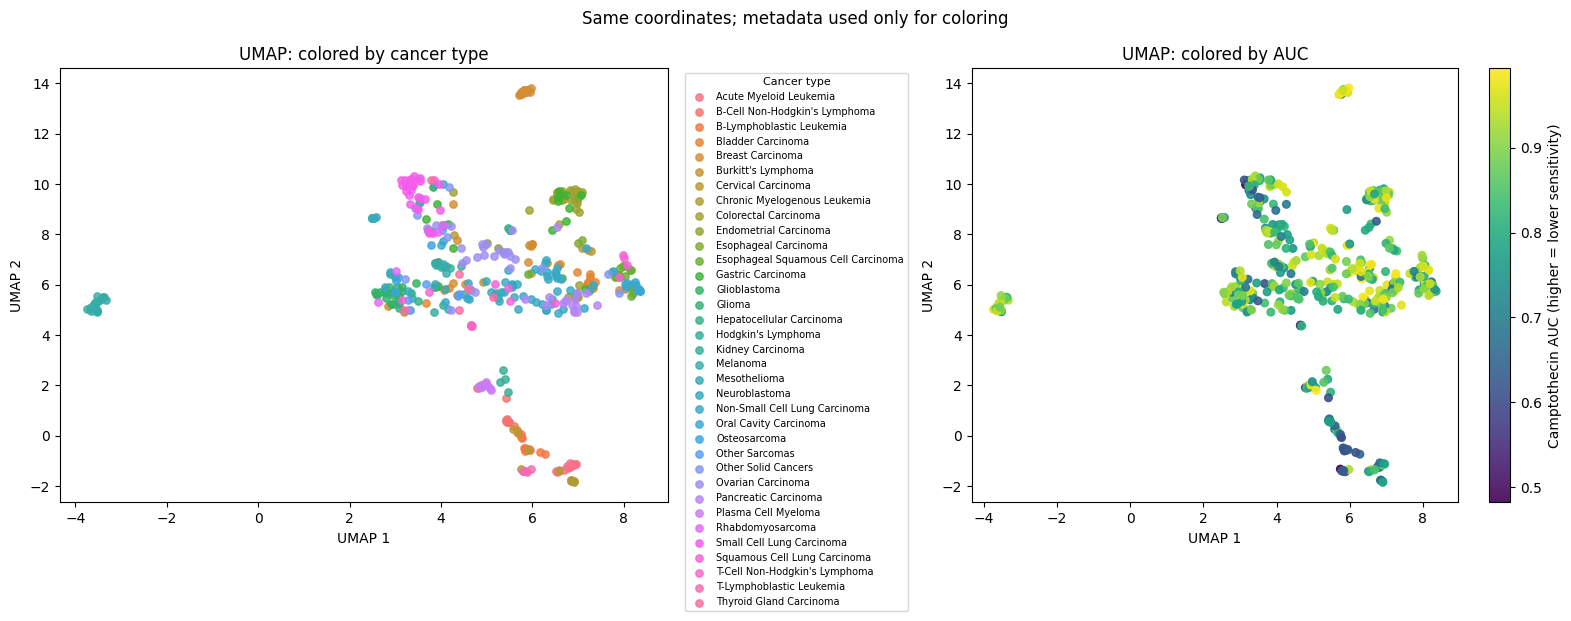

In [7]:
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "random_state": SEED,
    "transform_seed": SEED,
    "init": "spectral",
    "low_memory": True,
    "n_jobs": 1
}

umap_model = umap.UMAP(**UMAP_SETTINGS)
umap_coordinates = umap_model.fit_transform(pca_scores)

print("UMAP input: first", pca_scores.shape[1], "PCA components")
print("UMAP settings:")
for setting, value in UMAP_SETTINGS.items():
    print(f"{setting}: {value}")

plot_embedding(
    umap_coordinates,
    ("UMAP 1", "UMAP 2"),
    "UMAP"
)

Explain:These also use the same UMAP coordinates, colored once by cancer type and once by AUC.
- Nearby dots represent cell lines with similar expression profiles, according to UMAP.
- The cancer-type version shows whether nearby cell lines tend to share a cancer type.
- The AUC version shows whether nearby cell lines tend to have similar drug-response values.
UMAP 1 and UMAP 2 are map coordinates, not individual genes. UMAP emphasizes local neighborhoods, so interpret nearby groups more than the overall distance between far-apart groups. **bold text**

8. Save the coordinates
This saves each training cell line’s PCA and UMAP coordinates alongside its ID, cancer type, and AUC. The metadata are included for interpretation, not used to calculate the coordinates.

In [8]:
coordinates = plot_metadata.copy()
coordinates["PC1"] = pca_coordinates[:, 0]
coordinates["PC2"] = pca_coordinates[:, 1]
coordinates["UMAP1"] = umap_coordinates[:, 0]
coordinates["UMAP2"] = umap_coordinates[:, 1]

output_file = "pca_umap_training_coordinates.csv"
coordinates.to_csv(output_file, index=False)

print("Saved:", output_file)
files.download(output_file)

Saved: pca_umap_training_coordinates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

t-SNE input: first 50 PCA components
t-SNE settings:
n_components: 2
perplexity: 30
learning_rate: auto
init: pca
metric: euclidean
random_state: 42


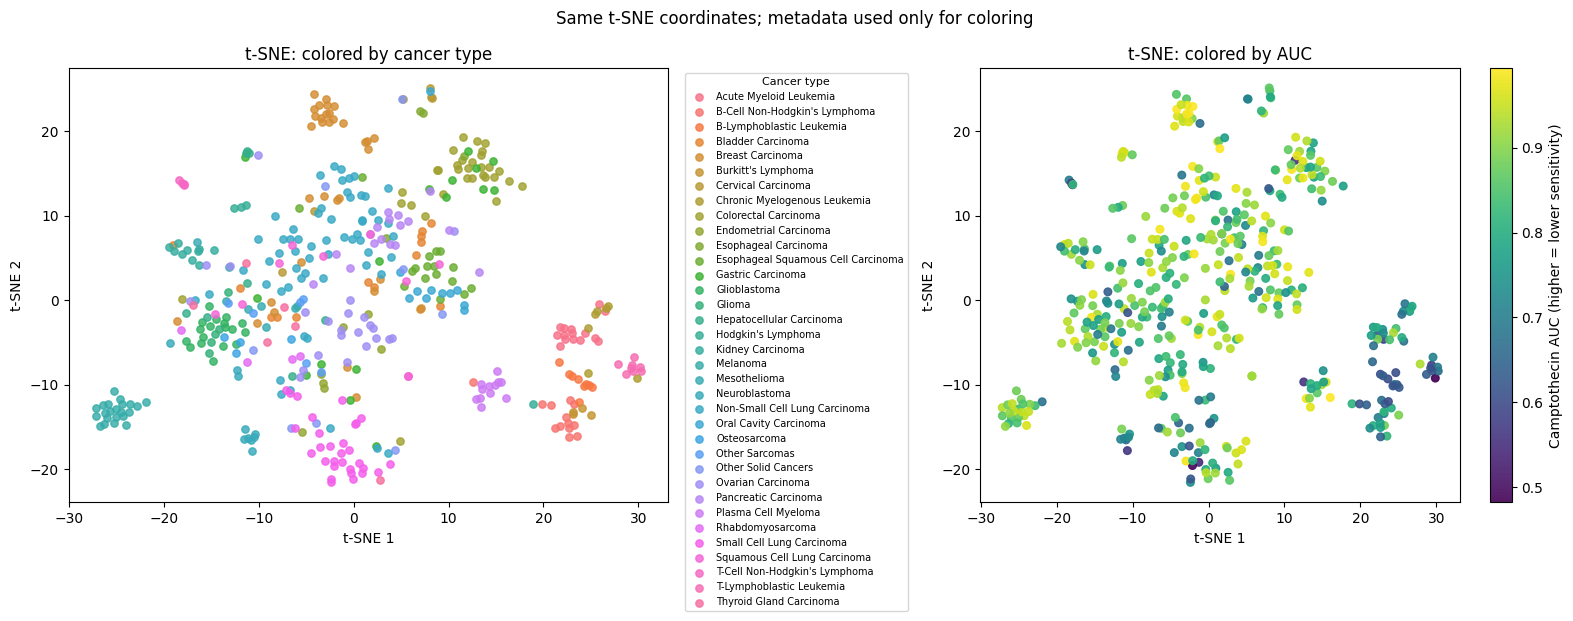

In [13]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Fixed settings for reproducibility
TSNE_SETTINGS = {
    "n_components": 2,
    "perplexity": 30,
    "learning_rate": "auto",
    "init": "pca",
    "metric": "euclidean",
    "random_state": 42
}

if TSNE_SETTINGS["perplexity"] >= len(pca_scores):
    raise ValueError("Perplexity must be smaller than the number of cell lines.")

# Fit t-SNE using expression-derived PCA scores only
tsne_model = TSNE(**TSNE_SETTINGS)
tsne_coordinates = tsne_model.fit_transform(pca_scores)

print("t-SNE input: first", pca_scores.shape[1], "PCA components")
print("t-SNE settings:")
for setting, value in TSNE_SETTINGS.items():
    print(f"{setting}: {value}")

# Use the same t-SNE coordinates in both plots
cancer_types = plot_metadata["cancer_type"].astype(str).to_numpy()
auc_values = plot_metadata["AUC"].to_numpy(dtype=float)
categories = sorted(np.unique(cancer_types))
colors = sns.color_palette("husl", n_colors=len(categories))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: color by cancer type
for cancer, color in zip(categories, colors):
    mask = cancer_types == cancer
    axes[0].scatter(
        tsne_coordinates[mask, 0],
        tsne_coordinates[mask, 1],
        color=color,
        label=cancer,
        s=28,
        alpha=0.82
    )

axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
axes[0].set_title("t-SNE: colored by cancer type")
axes[0].legend(
    title="Cancer type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=7,
    title_fontsize=8
)

# Plot 2: color by continuous AUC
points = axes[1].scatter(
    tsne_coordinates[:, 0],
    tsne_coordinates[:, 1],
    c=auc_values,
    cmap="viridis",
    s=30,
    alpha=0.9
)

colorbar = fig.colorbar(points, ax=axes[1])
colorbar.set_label("Camptothecin AUC (higher = lower sensitivity)")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
axes[1].set_title("t-SNE: colored by AUC")

fig.suptitle("Same t-SNE coordinates; metadata used only for coloring")
plt.tight_layout()
plt.show()

Explain:These use the same t-SNE coordinates, again colored by cancer type and AUC.
- Nearby dots represent cell lines with similar expression profiles in the t-SNE map.
- The two colors show whether those nearby lines also tend to share cancer types or AUC values.
Like UMAP, t-SNE axes do not have direct biological units. The map is exploratory; it does not measure prediction accuracy. **bold text**